# Random intervals

Quantiles of random intervals on the real line, the graphical outputs compares the two approaches:

 - **halfspace-based quantiles** (blue), defined through the support functions in the directions $\pm 1$;
 - **coverage-based quantiles** (red), the level sets $\{x : \mathsf P(x \in X) \ge \alpha\}$,

 *Requires:* `numpy`, `matplotlib`, a LaTeX installation (for figure labels).

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from IntervalRandomSet import Interval, IntervalRandomSet
from utils import set_plotting_style, save_figure

set_plotting_style()

SAVE_FIGURES = False   # set to True to export the figures used in the paper (folder /images must exist)

rng = np.random.default_rng(2026)   # one shared generator: run the cells in order to reproduce the figures

alphas = np.linspace(0, 1, 101)

### 1. Example 3: Interval with a Gaussian center
$X = [Y - c,\ Y + c]$ with $Y \sim N(0, 1)$ and half-width $c = 0.5$. The sample has 100,000 realizations.

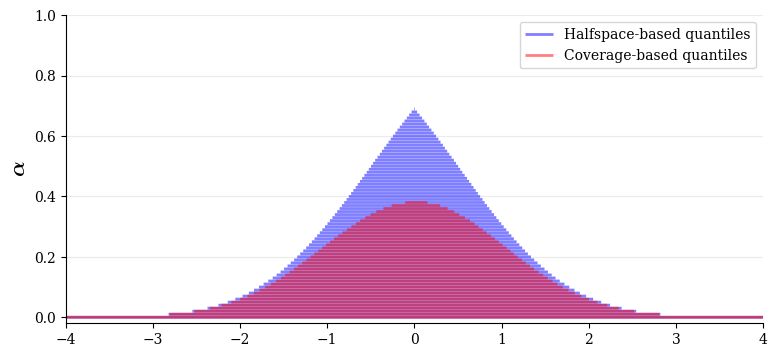

In [8]:
def gaussian_interval(c):
    """Interval [Y - c, Y + c] with Y ~ N(0, 1) and half-width c > 0."""
    if c <= 0:
        raise ValueError("c must be positive")
    y = rng.normal()
    return Interval(y - c, y + c)

RS = IntervalRandomSet([gaussian_interval(0.5) for _ in range(100_000)])
RS.plot_quantiles(alphas=alphas, limits=(-4, 4))
if SAVE_FIGURES: save_figure(plt.gcf(), "images/rand_interval")
plt.show()

### 2. Further examples (demonstration only)
Each sample has 10,000 realizations. The interval endpoints are:

1. $\min(U_1, U_2)$ and $\max(U_1, U_2)$ with $U_1 \sim U(0, 1)$, $U_2 \sim U(0, 2)$;
2. two independent standard Cauchy variables (heavy tails, hence wider axis limits);
3. left endpoint $-E_1$ with $E_1 \sim \mathrm{Exp}(1)$, right endpoint $E_2 \sim \mathrm{Exp}(10)$.

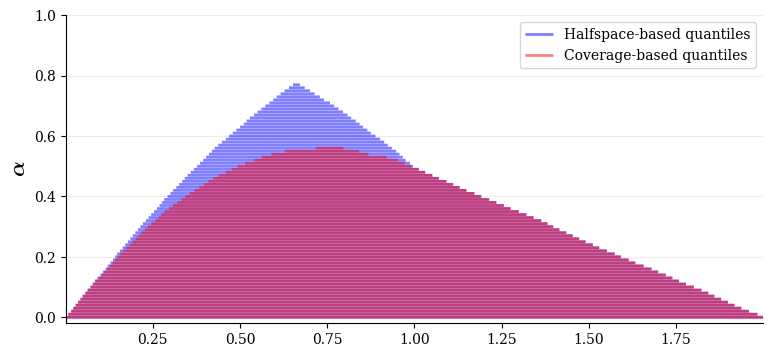

In [4]:
def uniform_interval():
    """Interval between a ~ U(0, 1) and b ~ U(0, 2)."""
    a = rng.random()
    b = 2 * rng.random()
    return Interval(min(a, b), max(a, b))

RS1 = IntervalRandomSet([uniform_interval() for _ in range(10_000)])
RS1.plot_quantiles(alphas=alphas)
plt.show()

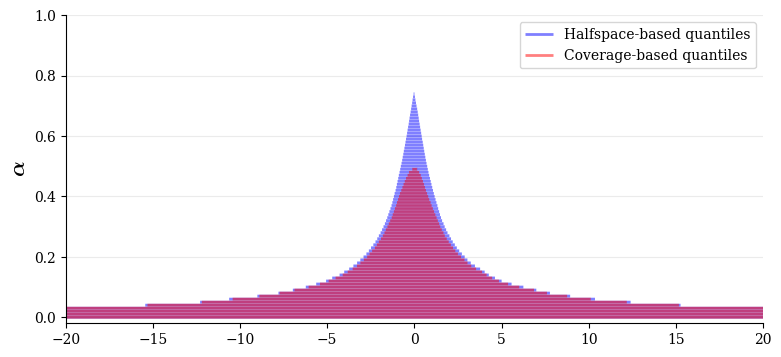

In [5]:
def cauchy_interval():
    """Interval between two independent standard Cauchy variables."""
    a, b = rng.standard_cauchy(2)
    return Interval(min(a, b), max(a, b))

RS2 = IntervalRandomSet([cauchy_interval() for _ in range(10_000)])
RS2.plot_quantiles(alphas=alphas, limits=(-20, 20))
plt.show()

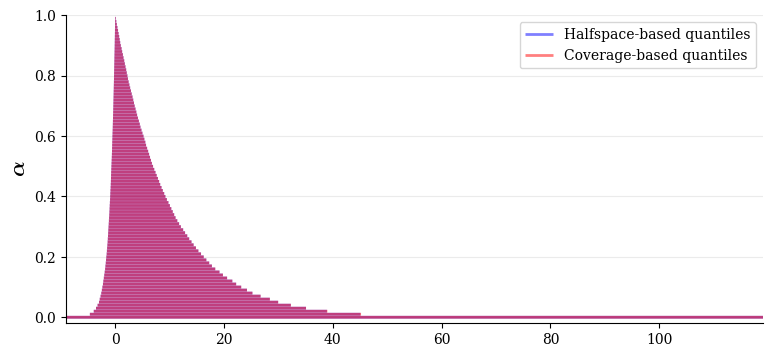

In [6]:
def exponential_interval():
    """Interval [-E1, E2] with E1 ~ Exp(1) and E2 ~ Exp(10)."""
    a = -rng.exponential()
    b = rng.exponential(10)
    return Interval(a, b)

RS3 = IntervalRandomSet([exponential_interval() for _ in range(10_000)])
RS3.plot_quantiles(alphas=alphas)
plt.show()